正在执行升级版技能自动提取...
提取完成！
✅ 已导出 machine_extraction_results_A2.csv 供 M7 验证！
总岗位数: 194, 明确要求AI的岗位数: 17


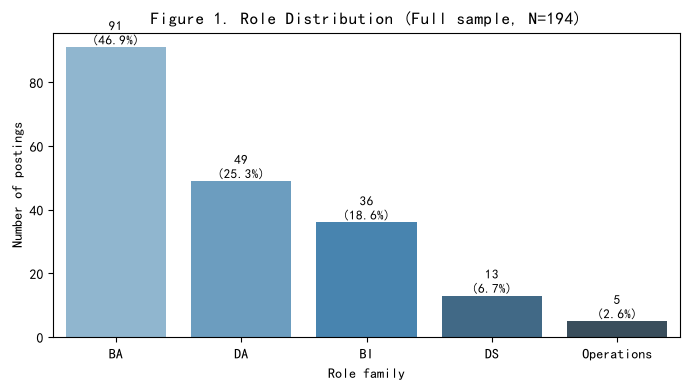

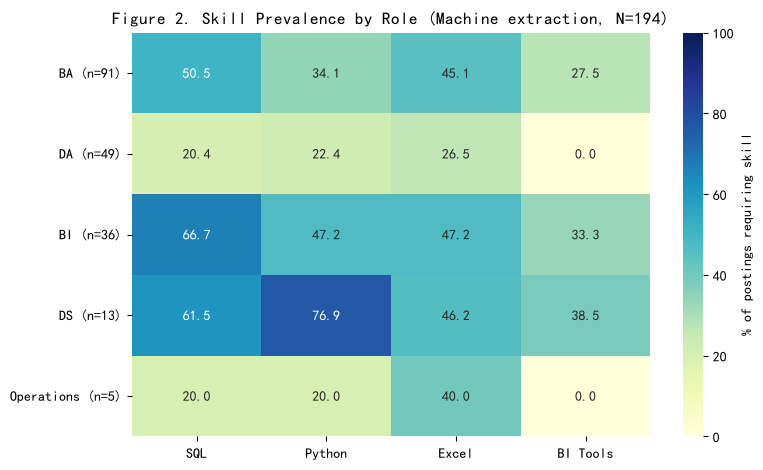

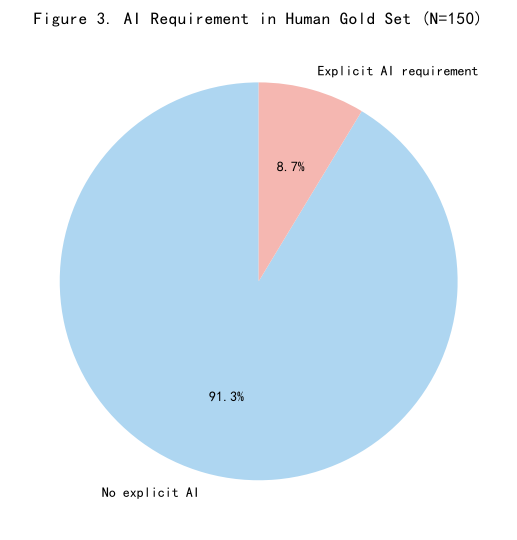


=== Gold Set 真实统计 (N=150) ===
gold_ai_flag
0    137
1     13
Name: count, dtype: int64
gold_ai_flag
0    91.3
1     8.7
Name: count, dtype: float64


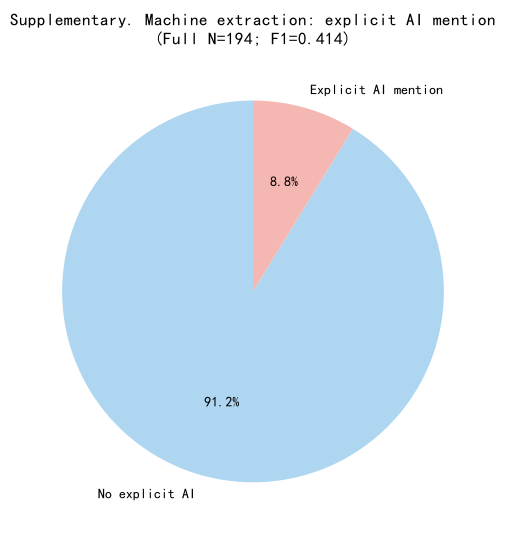

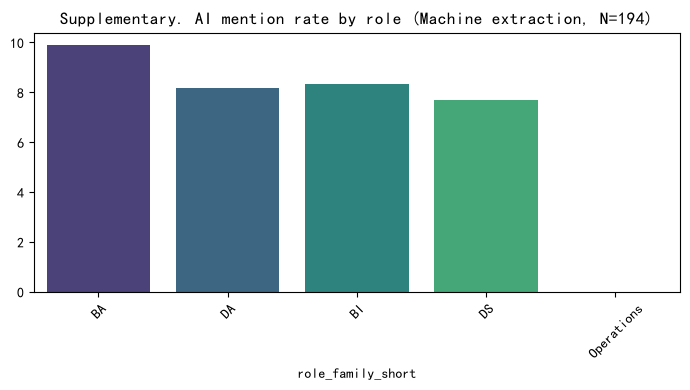


薪资分布：
count       193.000000
mean      27895.077720
std       43863.732398
min        4500.000000
1%         5000.000000
5%         6300.000000
25%        9000.000000
50%       15000.000000
75%       30000.000000
95%      126000.000000
99%      225000.000000
max      325000.000000
Name: salary_mid_monthly, dtype: float64

过滤后 AI vs 非AI 薪资统计：
               count   median          mean
has_AI_Skills                              
0                169  13500.0  17613.905325
1                 12  18250.0  19750.000000


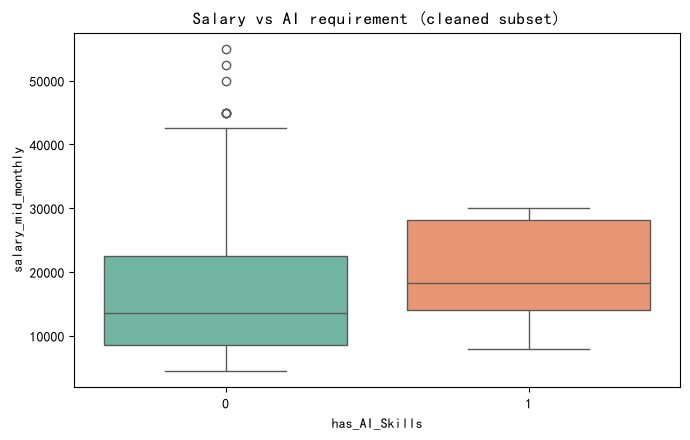

In [12]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# 1. 读取数据
df = pd.read_csv('../data/cleaned/clean_pool_for_gold_set.csv')

# 2. 升级版自动提取逻辑
def extract_skills_advanced(text):
    text = str(text).lower()
    results = {}
    
    # --- 基础技能库 (去掉 \b，改为直接包含匹配，兼容中英文混排) ---
    results['has_SQL'] = int(bool(re.search(r'sql|mysql|hive', text)))
    results['has_Python'] = int(bool(re.search(r'python|pandas', text)))
    results['has_Excel'] = int(bool(re.search(r'excel|数据透视表', text)))
    results['has_BI_Tools'] = int(bool(re.search(r'tableau|power\s*bi|帆软|quickbi|观远|bi工具', text)))
    
    # --- AI 技能特殊处理 ---
    # 只要出现以下词，就视为提到了 AI
    ai_keywords = r'人工智能|\bai\b|aigc|llm|大模型|chatgpt|claude|cursor|agent|智能问数|prompt|提示词|rag|知识图谱'
    
    if re.search(ai_keywords, text):
        # 判断上下文：如果明确写了“加分、优先、plus”，且离 AI 词很近（前后15个字符内）
        exclude_words = r'加分|优先|plus|preferred|nice\s*to\s*have|更佳'
        is_plus = False
        
        # 抓取包含 AI 关键词及前后的文本片段进行判断
        matches = re.finditer(rf'.{{0,15}}({ai_keywords}).{{0,15}}', text)
        for match in matches:
            context = match.group(0)
            if re.search(exclude_words, context):
                is_plus = True
                break
                
        # 逻辑：只要提到了 AI，且不是作为“加分项”出现的，统统记为 1
        # (因为一旦提到了，哪怕只是说“探索AI”，在简历筛选中也是强相关指标，后续通过M7验证去修正)
        if is_plus:
            results['has_AI_Skills'] = 0
        else:
            results['has_AI_Skills'] = 1
    else:
        results['has_AI_Skills'] = 0
        
    return pd.Series(results)

print("正在执行升级版技能自动提取...")
df = pd.concat([df, df['jd_text'].apply(extract_skills_advanced)], axis=1)
print("提取完成！")

# ================= 3. 导出机器提取结果 (给 B 做验证用) =================
export_cols = ['record_id', 'job_title_standardized', 'has_SQL', 'has_Python', 'has_Excel', 'has_BI_Tools', 'has_AI_Skills']
df[export_cols].to_csv('../data/documentation/machine_extraction_results_A2.csv', index=False, encoding='utf-8-sig')
print("✅ 已导出 machine_extraction_results_A2.csv 供 M7 验证！")

# 快速看一下提取了多少个 AI 岗位
print(f"总岗位数: {len(df)}, 明确要求AI的岗位数: {df['has_AI_Skills'].sum()}")


# ================= 4. EDA =================
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('../reports/figures', exist_ok=True)
os.makedirs('../reports/tables', exist_ok=True)

# 1. 统一角色顺序（修复你截图里的 0 值 BUG）
role_map = {
    'Business Analyst': 'BA',
    'Data Analyst': 'DA',
    'BI Analyst': 'BI',
    'Data Science': 'DS',
    'Operations Analyst': 'Operations'
}
df['role_family_short'] = df['role_family'].map(role_map).fillna(df['role_family'])
role_order = ['BA', 'DA', 'BI', 'DS', 'Operations']

role_counts = df['role_family_short'].value_counts().reindex(role_order).fillna(0).astype(int)
role_pct = role_counts / role_counts.sum() * 100

# ---------- Figure 1: Role Distribution ----------
plt.figure(figsize=(7, 4))
ax = sns.barplot(
    x=role_counts.index,
    y=role_counts.values,
    hue=role_counts.index,
    palette='Blues_d',
    legend=False
)
for i, v in enumerate(role_counts.values):
    ax.text(i, v, f'{v}\n({role_pct.iloc[i]:.1f}%)', ha='center', va='bottom', fontsize=9)
plt.title('Figure 1. Role Distribution (Full sample, N=194)')
plt.xlabel('Role family')
plt.ylabel('Number of postings')
plt.tight_layout()
plt.savefig('../reports/figures/Figure1_Role_Distribution_A2.png', dpi=200, bbox_inches='tight')
plt.show()

# ---------- Figure 2: Skill Prevalence by Role ----------
skill_cols = ['has_SQL', 'has_Python', 'has_Excel', 'has_BI_Tools']
skill_matrix = (
    df.groupby('role_family_short')[skill_cols]
      .mean()
      .reindex(role_order) * 100
)
skill_matrix = skill_matrix.rename(columns={
    'has_SQL': 'SQL', 'has_Python': 'Python',
    'has_Excel': 'Excel', 'has_BI_Tools': 'BI Tools'
})
skill_matrix.index = [f'{r} (n={role_counts.get(r, 0)})' for r in skill_matrix.index]

plt.figure(figsize=(8, 4.8))
sns.heatmap(
    skill_matrix, annot=True, fmt='.1f', cmap='YlGnBu',
    vmin=0, vmax=100, cbar_kws={'label': '% of postings requiring skill'}
)
plt.title('Figure 2. Skill Prevalence by Role (Machine extraction, N=194)')
plt.tight_layout()
plt.savefig('../reports/figures/Figure2_Skill_Heatmap_A2.png', dpi=200, bbox_inches='tight')
plt.show()

# ---------- Figure 3: AI Prevalence in Gold Set (使用真实文件) ----------
# 读取 B 同学的 150 条 Gold Set 真实文件
gold_150 = pd.read_csv('../data/documentation/Goldset_Coder_B_150.csv')
ai_col = 'gold_ai_flag'

# 画人工验证的 Gold Set 饼图
ai_gold_counts = gold_150[ai_col].value_counts().reindex([0, 1]).fillna(0).astype(int)
ai_gold_pct = ai_gold_counts / ai_gold_counts.sum() * 100

plt.figure(figsize=(5.5, 5.5))
plt.pie(
    ai_gold_counts.values,
    labels=['No explicit AI', 'Explicit AI requirement'],
    autopct='%1.1f%%', colors=['#aed6f1', '#f5b7b1'], startangle=90
)
plt.title(f'Figure 3. AI Requirement in Human Gold Set (N={len(gold_150)})')
plt.tight_layout()
plt.savefig('../reports/figures/Figure3_AI_GoldSet_A2.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"\n=== Gold Set 真实统计 (N={len(gold_150)}) ===")
print(ai_gold_counts)
print(ai_gold_pct.round(1))

# ---------- Supplementary: Machine extraction full N=194 ----------
machine_ai_counts = df['has_AI_Skills'].value_counts().reindex([0, 1]).fillna(0).astype(int)
plt.figure(figsize=(5.5, 5.5))
plt.pie(
    machine_ai_counts.values,
    labels=['No explicit AI', 'Explicit AI mention'],
    autopct='%1.1f%%', colors=['#aed6f1', '#f5b7b1'], startangle=90
)
plt.title(f'Supplementary. Machine extraction: explicit AI mention\n(Full N={len(df)}; F1=0.414)')
plt.tight_layout()
plt.savefig('../reports/figures/Supplementary_AI_Machine_Full_A2.png', dpi=200, bbox_inches='tight')
plt.show()

# ---------- Supplementary: AI by role ----------
ai_by_role = (
    df.groupby('role_family_short')['has_AI_Skills']
      .mean().reindex(role_order) * 100
)
plt.figure(figsize=(7, 4))
sns.barplot(x=ai_by_role.index, y=ai_by_role.values, hue=ai_by_role.index, palette='viridis', legend=False)
plt.title('Supplementary. AI mention rate by role (Machine extraction, N=194)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../reports/figures/Supplementary_AI_by_Role_A2.png', dpi=200, bbox_inches='tight')
plt.show()

# ---------- Salary plot ----------
print('\n薪资分布：')
print(df['salary_mid_monthly'].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

df_salary = df[(df['salary_mid_monthly'] >= 3000) & (df['salary_mid_monthly'] <= 60000)].copy()
print('\n过滤后 AI vs 非AI 薪资统计：')
print(df_salary.groupby('has_AI_Skills')['salary_mid_monthly'].agg(['count', 'median', 'mean']))

group_n = df_salary.groupby('has_AI_Skills').size()
if group_n.min() >= 10:
    plt.figure(figsize=(7, 4.5))
    sns.boxplot(x='has_AI_Skills', y='salary_mid_monthly', data=df_salary, hue='has_AI_Skills', palette='Set2', legend=False)
    plt.title('Salary vs AI requirement (cleaned subset)')
    plt.tight_layout()
    plt.savefig('../reports/figures/Supplementary_Salary_vs_AI_A2.png', dpi=200, bbox_inches='tight')
    plt.show()
else:
    print('AI 组样本太少，跳过箱线图；正文用文字说明。')

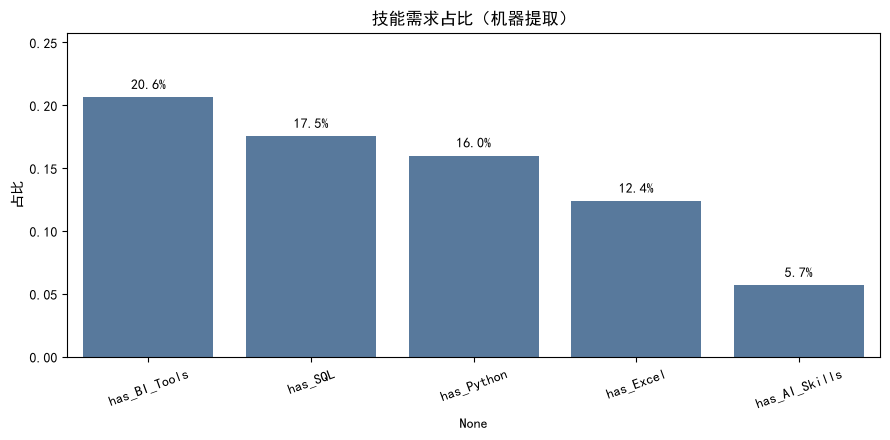